<a href="https://colab.research.google.com/github/aditya01-dev/Natural-Language-Processing-Lab/blob/main/NLP_Practical_23_Attention_Mechanism.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vocabulary Size: 32
Maximum Sequence Length: 7
Input Shape: (12, 7)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attention_layer' (of type AttentionLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 7, 16)          │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ [(None, 16), (None, 7, │            17 │
│ (AttentionLayer)                │ 1)]                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 818 (3.20 KB)

 Trainable params: 818 (3.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5000 - loss: 0.6954
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5000 - loss: 0.6926
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5000 - loss: 0.6912
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5000 - loss: 0.6900
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5000 - loss: 0.6889
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5000 - loss: 0.6879
Epoch 7/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5000 - loss: 0.6869
Epoch 8/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5000 - loss: 0.6858
Epoch 9/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6667 - loss: 0.6846
Epoch 10/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7500 - loss: 0.6834
Epoch 11/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8333 - loss: 0.6821
Epoch 12/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9167 - loss: 0.6808
E

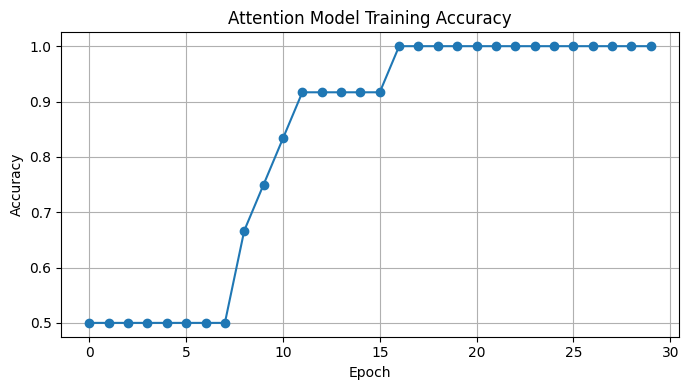


ATTENTION WEIGHTS:
i               0.1324
really          0.1519
love            0.1455
this            0.1479
amazing         0.1504
movie           0.1317
<PAD>           0.1402


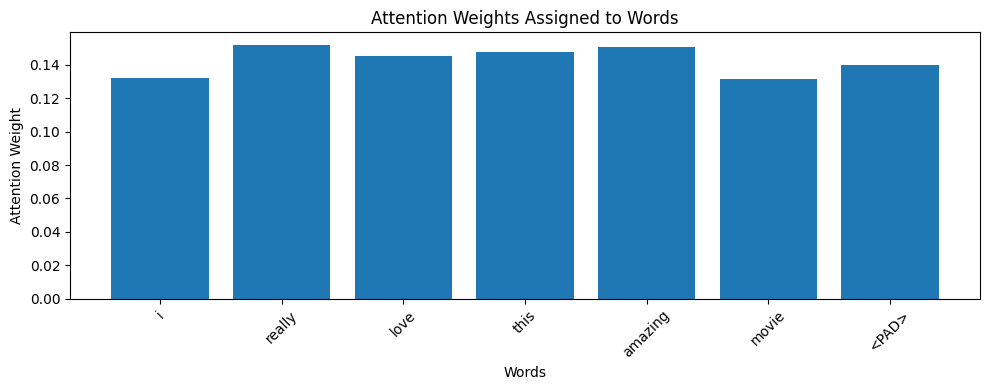


NEW TEXT: this movie is fantastic and enjoyable
Prediction Score: 0.5121
Predicted Sentiment: Positive

RESULT:
A custom attention mechanism was implemented and trained.

CONCLUSION:
The attention mechanism assigns importance weights to input
tokens and forms a context representation for classification.


In [ ]:
# ============================================================
# PRACTICAL 23: BASIC CUSTOM ATTENTION MECHANISM
# Course Outcome: CO2
# ============================================================
# Name: Aditya kumar Singh
# OBJECTIVE:
# To implement a basic attention mechanism for text classification
# and observe how attention weights highlight important words.

!pip -q install tensorflow

# Import libraries
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, Dense, GlobalAveragePooling1D,
    Layer
)

tf.random.set_seed(42)
np.random.seed(42)

# ------------------------------------------------------------
# 1. PREPARE DATASET
# ------------------------------------------------------------

texts = [
    "this movie is excellent and wonderful",
    "i really love this amazing movie",
    "the film was fantastic and enjoyable",
    "this movie is great and beautiful",
    "the acting is brilliant and excellent",
    "i enjoyed this wonderful movie",
    "this movie is terrible and boring",
    "i hate this awful film",
    "the film was horrible and very bad",
    "this movie is poor and boring",
    "the acting is disappointing and terrible",
    "i disliked this awful movie"
]

labels = np.array([1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0])

# 1 = Positive, 0 = Negative

# ------------------------------------------------------------
# 2. TOKENIZATION AND PADDING
# ------------------------------------------------------------

tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)
max_length = max(len(seq) for seq in sequences)

X = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary Size:", vocab_size)
print("Maximum Sequence Length:", max_length)
print("Input Shape:", X.shape)

# ------------------------------------------------------------
# 3. CUSTOM ATTENTION LAYER
# ------------------------------------------------------------

class AttentionLayer(Layer):

    def build(self, input_shape):
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(1,),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):
        scores = tf.nn.tanh(tf.matmul(inputs, self.W) + self.b)
        weights = tf.nn.softmax(scores, axis=1)
        context = tf.reduce_sum(inputs * weights, axis=1)
        return context, weights

# ------------------------------------------------------------
# 4. BUILD ATTENTION MODEL
# ------------------------------------------------------------

input_layer = Input(shape=(max_length,))

embedding = Embedding(
    input_dim=vocab_size,
    output_dim=16,
    mask_zero=True
)(input_layer)

attention_context, attention_weights = AttentionLayer()(embedding)

output = Dense(16, activation="relu")(attention_context)
output = Dense(1, activation="sigmoid")(output)

model = Model(inputs=input_layer, outputs=output)

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ------------------------------------------------------------
# 5. TRAIN MODEL
# ------------------------------------------------------------

history = model.fit(
    X,
    labels,
    epochs=30,
    batch_size=4,
    verbose=1
)

# ------------------------------------------------------------
# 6. VISUALIZE TRAINING ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], marker="o")
plt.title("Attention Model Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. EXTRACT ATTENTION WEIGHTS
# ------------------------------------------------------------

attention_model = Model(
    inputs=model.input,
    outputs=model.get_layer(index=2).output[1]
)

sample_text = "i really love this amazing movie"

sample_sequence = tokenizer.texts_to_sequences([sample_text])

sample_padded = pad_sequences(
    sample_sequence,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

weights = attention_model.predict(sample_padded, verbose=0)[0].flatten()

tokens = tokenizer.word_index
reverse_word_index = {value: key for key, value in tokens.items()}

word_ids = sample_padded[0]
sample_words = [
    reverse_word_index.get(idx, "<PAD>")
    if idx != 0 else "<PAD>"
    for idx in word_ids
]

print("\nATTENTION WEIGHTS:")
for word, weight in zip(sample_words, weights):
    print(f"{word:15s} {weight:.4f}")

# ------------------------------------------------------------
# 8. ATTENTION VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 4))
plt.bar(sample_words, weights)
plt.title("Attention Weights Assigned to Words")
plt.xlabel("Words")
plt.ylabel("Attention Weight")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. CLASSIFY NEW TEXT
# ------------------------------------------------------------

test_text = "this movie is fantastic and enjoyable"

test_seq = tokenizer.texts_to_sequences([test_text])

test_padded = pad_sequences(
    test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

prediction = model.predict(test_padded, verbose=0)[0][0]

print("\nNEW TEXT:", test_text)
print("Prediction Score:", round(float(prediction), 4))
print("Predicted Sentiment:",
      "Positive" if prediction >= 0.5 else "Negative")

# ------------------------------------------------------------
# 10. RESULT AND CONCLUSION
# ------------------------------------------------------------

print("\nRESULT:")
print("A custom attention mechanism was implemented and trained.")

print("\nCONCLUSION:")
print("The attention mechanism assigns importance weights to input")
print("tokens and forms a context representation for classification.")